In [22]:
import numpy as np
import matplotlib.pyplot as plt

In [23]:
def hamiltonian_matrix(N,dx,potential_values):

    C = 1/(2*dx**2)

    hamiltonian = np.zeros((N,N))

    for i in range(N):

        hamiltonian[i,i] = 2*C + potential_values[i]

        if i > 0:
            hamiltonian[i,i-1] = -C

        if i < N-1:
            hamiltonian[i,i+1] = -C

    return hamiltonian

In [24]:
def step_potential(x,V0=1,step_position=2):
    x=np.array(x, dtype=float)
    v = np.where(x<step_position,0,V0)
    return v

In [25]:
def solve_step_potential( L,V0,X0,interior_points,state_number):

    if interior_points <= 0:
        raise ValueError("interior_points must be positive.")

    if state_number < 0 or state_number >= interior_points:
        raise ValueError("Invalid state_number.")
    if L <= 0:
        raise ValueError("length can not be negative.")

    dx = L/(interior_points+1)
    x = np.linspace(dx,L-dx,interior_points)
    x_full = np.linspace(0,L,interior_points+2)

    potential_values = step_potential(x,V0,X0)
    hamiltonian = hamiltonian_matrix(interior_points,dx,potential_values)

    eigenvalues,eigenvectors = np.linalg.eigh(hamiltonian)

    phi_interior = eigenvectors[:,state_number]
    energy = eigenvalues[state_number]

    phi = np.concatenate(([0],phi_interior,[0]))
    norm = np.sum(np.abs(phi)**2)*dx
    phi_norm = phi/np.sqrt(norm)

    return x_full, phi_norm, energy



    

In [26]:
x, phi, energy = solve_step_potential(4, 10, 2, 1000, 0)

print("Energy:", energy)
print("x:", x[:10])
print("phi:", phi[:10])

print("Are values finite?", np.all(np.isfinite(phi)))
print("Maximum:", np.max(phi))
print("Minimum:", np.min(phi))
print("Number of nonzero values:", np.count_nonzero(phi))

Energy: 0.9945668757294572
x: [0.         0.003996   0.00799201 0.01198801 0.01598402 0.01998002
 0.02397602 0.02797203 0.03196803 0.03596404]
phi: [ 0.         -0.00533053 -0.01066089 -0.01599092 -0.02132043 -0.02664927
 -0.03197726 -0.03730424 -0.04263003 -0.04795446]
Are values finite? True
Maximum: 0.0
Minimum: -0.9458314008354808
Number of nonzero values: 1000


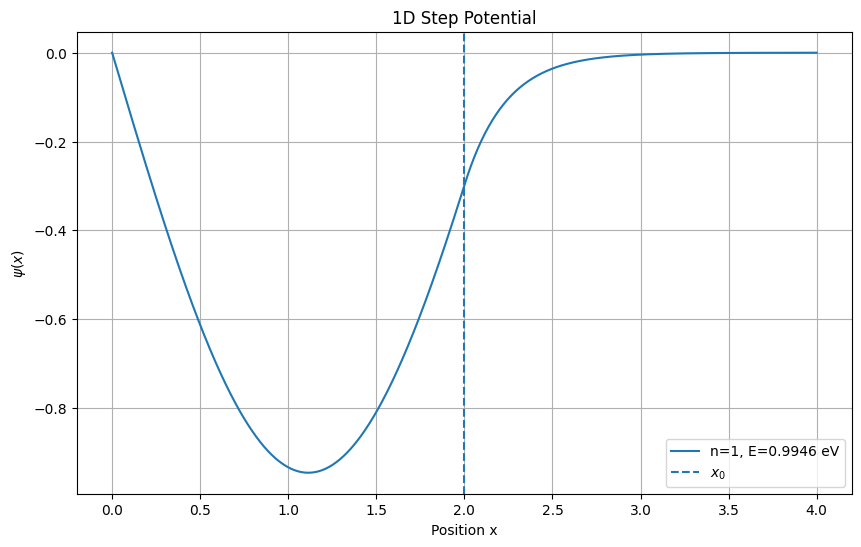

In [27]:
x0 = 2
state_number = 0
x, phi, energy = solve_step_potential(4, 10, x0, 1000, state_number)

plt.figure(figsize=(10,6))
plt.plot(x, phi,label=f"n={state_number+1}, E={energy:.4f} eV")
plt.axvline(x0, linestyle="--", label=r"$x_0$")
plt.xlabel("Position x")
plt.ylabel(r"$\psi(x)$")
plt.title("1D Step Potential")
plt.legend()
plt.grid(True)
plt.show()

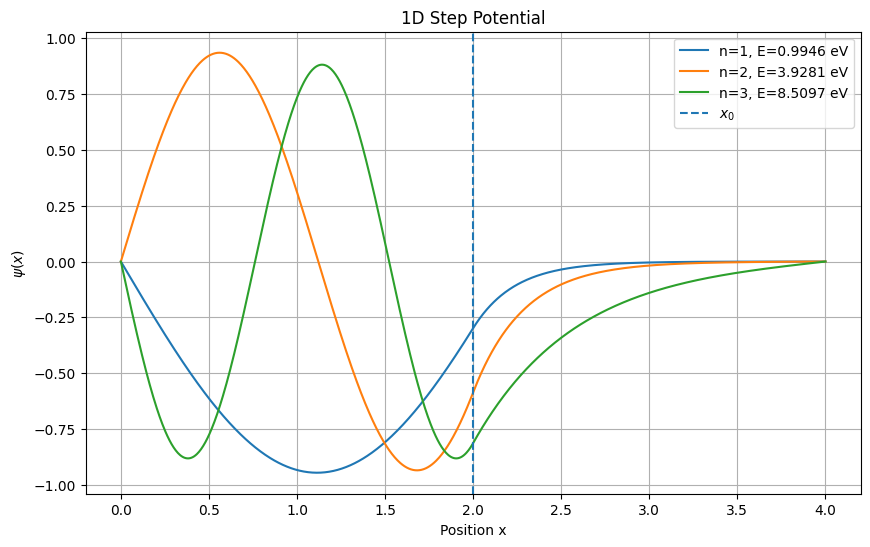

In [28]:
plt.figure(figsize=(10,6))

for i in range(3):
    x, phi, energy = solve_step_potential(4, 10, 2, 1000, i)
    plt.plot(x, phi, label=f"n={i+1}, E={energy:.4f} eV")

plt.axvline(2, linestyle="--", label=r"$x_0$")
plt.xlabel("Position x")
plt.ylabel(r"$\psi(x)$")
plt.title("1D Step Potential")
plt.legend()
plt.grid(True)
plt.show()

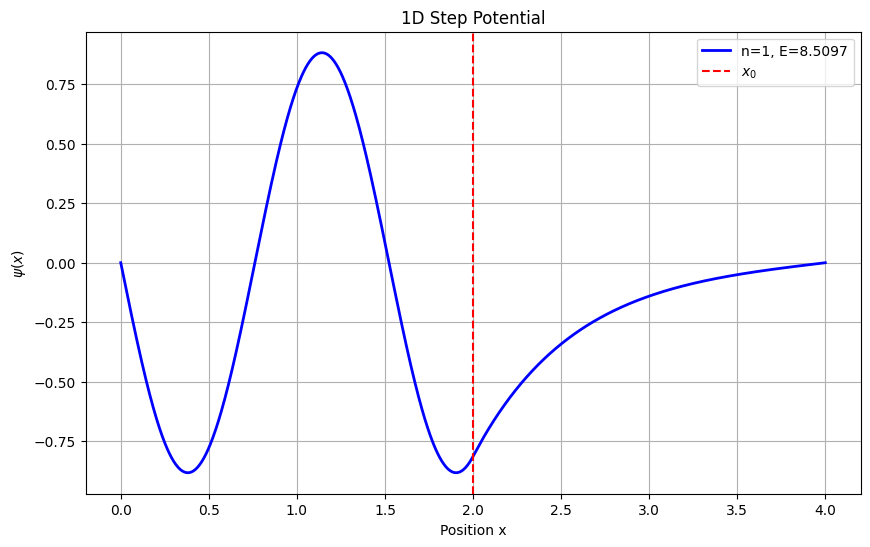

In [29]:
plt.figure(figsize=(10,6))

plt.plot(x, phi, color='blue', linewidth=2,
         label=f"n={state_number+1}, E={energy:.4f}")

plt.axvline(x0, linestyle="--", color='red', label="$x_0$")

plt.xlabel("Position x")
plt.ylabel(r"$\psi(x)$")
plt.title("1D Step Potential")

plt.legend()
plt.grid(True)
plt.show()

Energy: 0.9945668757294572
x shape: (1002,)
phi shape: (1002,)
Maximum wavefunction: 0.9458314008354808
First 10 wavefunction values: [ 0.         -0.00533053 -0.01066089 -0.01599092 -0.02132043 -0.02664927
 -0.03197726 -0.03730424 -0.04263003 -0.04795446]


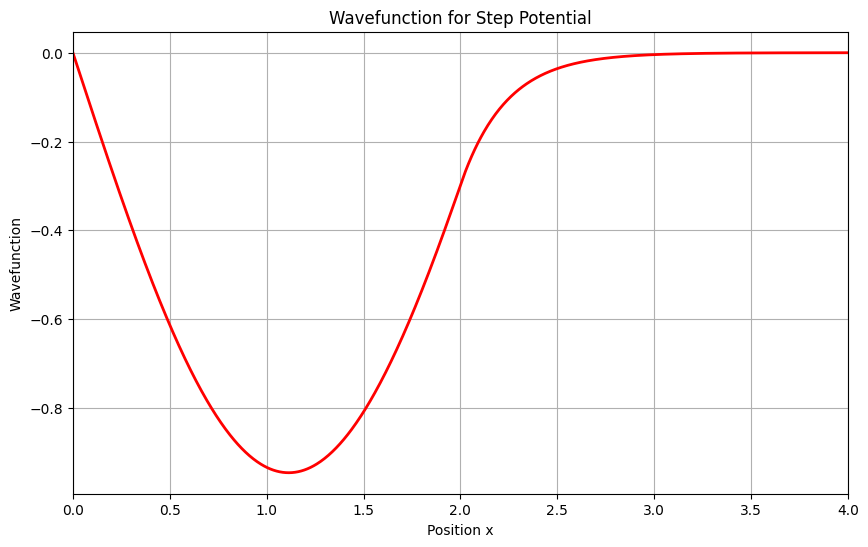

In [30]:
import numpy as np
import matplotlib.pyplot as plt

x, phi, energy = solve_step_potential(4, 10, 2, 1000, 0)

print("Energy:", energy)
print("x shape:", x.shape)
print("phi shape:", phi.shape)
print("Maximum wavefunction:", np.max(np.abs(phi)))
print("First 10 wavefunction values:", phi[:10])

plt.figure(figsize=(10, 6))
plt.plot(x, phi, 'r-', linewidth=2)
plt.xlim(0, 4)
plt.xlabel("Position x")
plt.ylabel("Wavefunction")
plt.title("Wavefunction for Step Potential")
plt.grid()
plt.show()